# Notebook 12 — Benchmark Score Data Entry (guided)

**Goal:** populate `outputs/measurements/benchmarks.csv` with each model's REPORTED benchmark scores transcribed from its original paper / technical report / leaderboard. The notebook is a structured data-entry workflow: it generates a YAML skeleton, lets you fill scores cell-by-cell, validates the entries against the schema, and exports the CSV consumed by notebook 13 (correlation analysis).

**Why we transcribe rather than re-run:** per supervisor feedback (memory.md), running benchmarks ourselves is OUT OF SCOPE. VQAv2 alone takes days on a single L40S; the full 8-benchmark × 20-model matrix would burn weeks of compute that the original authors already spent. The CORRECT methodology is to transcribe each model's self-reported numbers and treat them as authoritative — with source attribution for every cell so the correlation analysis is auditable.

**Sparsity is expected.** Each model reports a different subset of benchmarks (CLIP papers predate MMMU; ViLT predates everything; BLIP-2 doesn't report MathVista; the Qwen2.5-VL tech report is the most comprehensive). The sparse-by-design CSV is the input to notebook 13 which handles missing cells via `dropna` per-correlation.

**Inputs:**
* The 20-model roster (from `vlm_audit/models.py`).
* Your literature-reading effort: ~3-5 evenings of paper-table transcription.

**Outputs:**
* `../outputs/measurements/benchmarks.yaml` — human-editable canonical record (one block per model).
* `../outputs/measurements/benchmarks.csv` — long-form CSV (one row per filled cell) consumed by notebook 13.
* `../outputs/measurements/benchmarks_provenance.md` — auto-generated audit trail grouped by source.

**Compute:** CPU only. No models loaded.

**Runtime:** a few minutes of cell execution. The TIME COST is reading papers — budget 15-25 minutes per model once you know where each paper hides its benchmark table.

**How to read this notebook:** §1-4 are setup + the benchmark roster. §5 is the per-model source-of-truth guide (paper section + URL per model). §6-7 generate the YAML skeleton. §8-9 are the PRE-POPULATED example cells (10-15 verified entries to bootstrap; you ADD more cells like these for the remaining models). §10-12 validate + save. §13 is the coverage heatmap that shows you visually where the data gaps still are.

---
## 1. Setup

Standard boilerplate. CPU-only. No GPU needed and no models loaded — this notebook is pure data entry + validation.

In [1]:
# Runpod / Colab setup. If you're on a local box with deps already installed, the %%capture line is harmless.
# %%capture
# !pip install -q pyyaml pandas numpy matplotlib seaborn

In [2]:
import os, sys, json, copy
from pathlib import Path
from datetime import date

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
LOG_DIR = CODE_ACTIVE / 'outputs' / 'logs'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
for d in (MEASUREMENT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Working dir:    {NB_DIR}')
print(f'code_active:    {CODE_ACTIVE}')
print(f'Measurements:   {MEASUREMENT_DIR}')

Working dir:    /workspace/code_active/notebooks
code_active:    /workspace/code_active
Measurements:   /workspace/code_active/outputs/measurements


In [3]:
import pandas as pd
import numpy as np
import yaml
import matplotlib.pyplot as plt

from vlm_audit import MODELS

print(f'pandas:         {pd.__version__}')
print(f'numpy:          {np.__version__}')
print(f'Models loaded:  {len(MODELS)}')
print(f'Date:           {date.today().isoformat()}')

pandas:         3.0.3
numpy:          2.1.2
Models loaded:  20
Date:           2026-05-22


---
## 2. Schema helpers (for consistency with notebooks 02-05)

These helpers aren't strictly needed for data entry (no FLOPs / no schema-aware aggregation here), but keeping the same imports/helpers visible makes it easier to chain cells across notebooks. The `schema_for()` function below tags each model so we can later filter benchmarks by schema (e.g. native_fused models may report different benchmark mixes than standard adapter-LLM models).

In [4]:
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

def safe_sum(d: dict, keys) -> float:
    return sum((d.get(k) or 0) for k in keys)

# Sanity check
assert schema_for('native_early_fusion') == 'native_fused'
assert schema_for('adapter_llm') == 'standard_vflh'
print('schema_for() ready.')
print('safe_sum() ready.')

schema_for() ready.
safe_sum() ready.


---
## 3. The 8 benchmarks — what they measure

We standardize on the 8 most-cited multimodal benchmarks that recent (2023+) VLM papers consistently report. Each benchmark has a short slug used as the column key in `benchmarks.csv`:

| Slug | Full name | What it measures | Typical score range | Source URL |
|---|---|---|---|---|
| `vqav2` | VQAv2 test-dev | General visual question answering | 60-85% accuracy | https://visualqa.org/ |
| `mmmu` | MMMU (val) | Multi-discipline college-level knowledge | 25-65% accuracy | https://mmmu-benchmark.github.io/ |
| `chartqa` | ChartQA (relaxed) | Chart + plot understanding | 30-90% relaxed acc | https://github.com/vis-nlp/ChartQA |
| `docvqa` | DocVQA (val ANLS) | Document VQA, OCR-heavy | 50-95% ANLS | https://www.docvqa.org/ |
| `mathvista` | MathVista (test-mini) | Math + visual reasoning | 20-70% accuracy | https://mathvista.github.io/ |
| `mmbench_en` | MMBench-EN (dev) | Broad multimodal capability | 30-85% accuracy | https://github.com/open-compass/MMBench |
| `seedbench` | SEED-Bench (image, overall) | Image perception | 30-80% accuracy | https://github.com/AILab-CVC/SEED-Bench |
| `ai2d` | AI2D (test) | Diagram understanding | 40-90% accuracy | https://allenai.org/data/diagrams |

**Score conventions used in this notebook:** all scores are 0-100 (percentages, not 0-1 fractions). If a paper reports 0.785 we record 78.5. If a paper reports VQAv2 in two splits (test-dev vs test-std) use test-dev. If a paper reports MMMU-Pro instead of MMMU, record under `mmmu` with a `'mmmu_pro variant'` note in the source field.

**MetricS to record per cell:** `score` (float, 0-100), `score_metric` (string, e.g. `'accuracy'` / `'ANLS'` / `'EM'` / `'relaxed_acc'`), `source_type` (`'paper'` / `'leaderboard'` / `'blog'` / `'model_card'`), `source_url`, `notes`.

In [5]:
BENCHMARKS = [
    ('vqav2',      'VQAv2 (test-dev)',          'General VQA',                'accuracy',    'https://visualqa.org/'),
    ('mmmu',       'MMMU (val)',                'Multi-discipline knowledge', 'accuracy',    'https://mmmu-benchmark.github.io/'),
    ('chartqa',    'ChartQA (relaxed)',         'Chart understanding',        'relaxed_acc', 'https://github.com/vis-nlp/ChartQA'),
    ('docvqa',     'DocVQA (val ANLS)',         'Document VQA / OCR-heavy',   'ANLS',        'https://www.docvqa.org/'),
    ('mathvista',  'MathVista (test-mini)',     'Math + visual reasoning',    'accuracy',    'https://mathvista.github.io/'),
    ('mmbench_en', 'MMBench-EN (dev)',          'Broad multimodal',           'accuracy',    'https://github.com/open-compass/MMBench'),
    ('seedbench',  'SEED-Bench (image)',        'Image perception',           'accuracy',    'https://github.com/AILab-CVC/SEED-Bench'),
    ('ai2d',       'AI2D (test)',               'Diagram understanding',      'accuracy',    'https://allenai.org/data/diagrams'),
]
BENCHMARK_SLUGS = [b[0] for b in BENCHMARKS]

print(f'Benchmarks: {len(BENCHMARKS)} canonical slugs')
for slug, name, desc, metric, url in BENCHMARKS:
    print(f'  {slug:12s}  {name:30s}  metric={metric:12s}  desc={desc}')

Benchmarks: 8 canonical slugs
  vqav2         VQAv2 (test-dev)                metric=accuracy      desc=General VQA
  mmmu          MMMU (val)                      metric=accuracy      desc=Multi-discipline knowledge
  chartqa       ChartQA (relaxed)               metric=relaxed_acc   desc=Chart understanding
  docvqa        DocVQA (val ANLS)               metric=ANLS          desc=Document VQA / OCR-heavy
  mathvista     MathVista (test-mini)           metric=accuracy      desc=Math + visual reasoning
  mmbench_en    MMBench-EN (dev)                metric=accuracy      desc=Broad multimodal
  seedbench     SEED-Bench (image)              metric=accuracy      desc=Image perception
  ai2d          AI2D (test)                     metric=accuracy      desc=Diagram understanding


---
## 4. Roster recap — the 20 models, sorted by family + year

Quick view of the roster so you know what you're transcribing for. Each row will become a YAML block; each model × benchmark cell will hold a `(score, source)` pair.

In [6]:
roster_df = pd.DataFrame([
    {
        'name':         m.name,
        'family':       m.family,
        'schema':       schema_for(m.family),
        'year':         m.release_year,
        'fp16_GB':      m.fits_in_gb_fp16,
        'hf_id':        m.hf_id,
        'notes':        m.notes,
    }
    for m in MODELS
])
print(f'Total models in roster: {len(roster_df)}')
print(f'Families: {sorted(roster_df.family.unique())}')
print(f'Schemas:  {roster_df.schema.value_counts().to_dict()}')
roster_df.sort_values(['family', 'year']).reset_index(drop=True)

Total models in roster: 20
Families: ['adapter_llm', 'adapter_llm_own_encoder', 'bridge_module', 'bridge_module_adapter_llm', 'bridge_module_precursor', 'cross_attention_llm', 'dual_encoder_contrastive', 'dynamic_tile_adapter_llm', 'moe_adapter_llm', 'native_decoupled_encoder', 'native_early_fusion', 'perceiver_adapter_llm', 'single_stream_fused']
Schemas:  {'standard_vflh': 18, 'native_fused': 1, 'decoupled_vision': 1}


,name,family,schema,year,fp16_GB,hf_id,notes
0,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,16.0,llava-hf/llava-1.5-7b-hf,
1,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,16.0,llava-hf/llava-v1.6-mistral-7b-hf,Multi-tile patching.
2,Molmo-7B-D,adapter_llm,standard_vflh,2024,16.0,allenai/Molmo-7B-D-0924,Fully-open data + weights. CLIP encoder + Qwen...
3,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,2024,24.0,mistral-community/pixtral-12b,Vision encoder trained from scratch. HF-conver...
4,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,7.0,Salesforce/blip2-opt-2.7b,Q-Former + frozen ViT-g + frozen OPT-2.7B.
5,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,17.0,Salesforce/instructblip-vicuna-7b,Instruction-tuned BLIP-2 with Vicuna-7B.
6,BLIP-large,bridge_module_precursor,standard_vflh,2022,1.0,Salesforce/blip-image-captioning-large,Precursor to BLIP-2.
7,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,18.0,HuggingFaceM4/idefics-9b,Perceiver Resampler + LLaMA-7B with gated cros...
8,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,standard_vflh,2024,22.0,meta-llama/Llama-3.2-11B-Vision-Instruct,Meta's official open multimodal. ViT + cross-a...
9,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,1.0,openai/clip-vit-large-patch14,


---
## 5. Recommended source-of-truth per model

This table is the user-facing data-entry guide. For each of the 20 models, it tells you exactly where to look. Most papers have a single canonical benchmark table (usually `Table 1` or `Table 4`); start there, then cross-check with the model's HuggingFace model card and the [OpenCompass leaderboard](https://opencompass.org.cn/) for sanity.

| Model | Primary source (paper) | Section | HF card | Leaderboard |
|---|---|---|---|---|
| CLIP-ViT-L/14 | Radford et al. 2021 | §3, Table 1 (zero-shot ImageNet only — no MMMU pre-2024) | https://huggingface.co/openai/clip-vit-large-patch14 | — |
| SigLIP-L/16 | Zhai et al. 2023 | §4, Table 2 (zero-shot tasks) | https://huggingface.co/google/siglip-large-patch16-384 | — |
| SigLIP2-So400m/14 | Tschannen et al. 2025 | §4, Table 4 | https://huggingface.co/google/siglip2-so400m-patch14-384 | — |
| BLIP-large | Li et al. 2022 | §5, Table 3 (VQAv2, captioning) | https://huggingface.co/Salesforce/blip-image-captioning-large | — |
| BLIP-2-OPT-2.7B | Li et al. 2023 | §4, Table 1 (VQAv2, OK-VQA) | https://huggingface.co/Salesforce/blip2-opt-2.7b | — |
| InstructBLIP-Vicuna-7B | Dai et al. 2023 | §5, Table 1 (held-out + held-in) | https://huggingface.co/Salesforce/instructblip-vicuna-7b | — |
| LLaVA-1.5-7B | Liu et al. 2023 (Improved Baselines) | §4, Table 1 | https://huggingface.co/llava-hf/llava-1.5-7b-hf | OpenCompass |
| LLaVA-NeXT-7B | Liu et al. 2024 blog | Blog post table 1 (https://llava-vl.github.io/blog/2024-01-30-llava-next/) | https://huggingface.co/llava-hf/llava-v1.6-mistral-7b-hf | OpenCompass |
| Molmo-7B-D | Deitke et al. 2024 | Tech report Table 1 | https://huggingface.co/allenai/Molmo-7B-D-0924 | OpenCompass |
| Qwen2-VL-7B | Wang et al. 2024 (Qwen2-VL TR) | §3, Table 4 | https://huggingface.co/Qwen/Qwen2-VL-7B-Instruct | OpenCompass |
| Qwen2.5-VL-7B | Bai et al. 2025 (Qwen2.5-VL TR) | §4, Table 1 (MOST comprehensive — all 8 benchmarks for 7B) | https://huggingface.co/Qwen/Qwen2.5-VL-7B-Instruct | OpenCompass |
| InternVL3-8B | Chen et al. 2025 (InternVL3 TR) | §4, Table 3 | https://huggingface.co/OpenGVLab/InternVL3-8B | OpenCompass |
| Pixtral-12B | Agrawal et al. 2024 | §4, Table 2 | https://huggingface.co/mistralai/Pixtral-12B-2409 | OpenCompass |
| IDEFICS-9B | Laurençon et al. 2023 (OBELICS) | §5, Table 5 (limited benchmarks) | https://huggingface.co/HuggingFaceM4/idefics-9b | — |
| Llama-3.2-11B-Vision | Meta 2024 (Llama 3 herd of models) | §6, Table 23 | https://huggingface.co/meta-llama/Llama-3.2-11B-Vision-Instruct | OpenCompass |
| Idefics2-8B | Laurençon et al. 2024 (What matters) | §4, Table 4 | https://huggingface.co/HuggingFaceM4/idefics2-8b | OpenCompass |
| DeepSeek-VL2-Small | Wu et al. 2024 (DeepSeek-VL2) | §4, Table 4 | https://huggingface.co/deepseek-ai/deepseek-vl2-small | OpenCompass |
| Chameleon-7B | Meta 2024 (Chameleon TR) | §6, Table 2 + Table 3 (small benchmark set; primarily image-gen focused) | https://huggingface.co/facebook/chameleon-7b | — |
| Janus-Pro-7B | DeepSeek 2025 (Janus-Pro) | §5, Table 4 | https://huggingface.co/deepseek-ai/Janus-Pro-7B | — |
| ViLT-B/32 | Kim et al. 2021 | §4, Table 4 (VQAv2 + NLVR2 only — pre-dates all 2023+ benchmarks) | https://huggingface.co/dandelin/vilt-b32-finetuned-vqa | — |

**Tips:**
* If the model's paper doesn't report a given benchmark, leave the cell `null` and add a note like `'not reported in paper — pre-dates MMMU'` or `'not reported in paper — would need to re-run'`.
* Some leaderboard numbers are post-hoc reproductions by third parties; PREFER the original paper number when available. If you take from a leaderboard, set `source_type='leaderboard'` and the URL.
* If the paper reports MULTIPLE numbers for the same benchmark (zero-shot vs fine-tuned, val vs test-dev, with-CoT vs without), pick the one most-commonly-cited and add a note.

---
## 6. YAML schema definition

The canonical record is a YAML file with one block per model. Each block has metadata (`model_name`, `hf_id`, `family`, `release_year`) plus a `benchmarks` dict keyed by benchmark slug. Each cell has 5 fields:

```yaml
- model_name: "CLIP-ViT-L/14"
  hf_id:      "openai/clip-vit-large-patch14"
  family:     "dual_encoder_contrastive"
  release_year: 2021
  benchmarks:
    vqav2:
      score: null               # 0-100 float, or null if not reported
      score_metric: accuracy    # accuracy / ANLS / EM / F1 / relaxed_acc
      source_type: paper        # paper / leaderboard / blog / model_card
      source_url: ""
      notes: "CLIP paper predates VQAv2-as-VLM-eval era"
    mmmu:
      score: null
      score_metric: accuracy
      source_type: paper
      source_url: ""
      notes: "CLIP predates MMMU (2024)"
    # ... 6 more benchmark slugs
```

Why YAML rather than JSON? Comments are allowed in YAML and the format is more human-editable. The notebook reads YAML → dict → DataFrame → CSV.

---
## 7. Generate the YAML skeleton (one entry per model × benchmark)

First-time setup: the cell below writes `benchmarks.yaml` if it doesn't already exist, with one block per model and all 8 benchmark slugs set to `score: null`. Re-running the cell will NOT clobber an existing filled-in file — it skips when the file exists.

If you want to FORCE regeneration (after editing the schema), delete `outputs/measurements/benchmarks.yaml` first.

In [7]:
YAML_PATH = MEASUREMENT_DIR / 'benchmarks.yaml'

def build_skeleton():
    """Return the canonical empty skeleton as a list of dicts."""
    out = []
    for m in MODELS:
        block = {
            'model_name':   m.name,
            'hf_id':        m.hf_id,
            'family':       m.family,
            'release_year': m.release_year,
            'benchmarks':   {},
        }
        for slug, name, _desc, metric, url in BENCHMARKS:
            block['benchmarks'][slug] = {
                'score':        None,
                'score_metric': metric,
                'source_type':  'paper',
                'source_url':   '',
                'notes':        '',
            }
        out.append(block)
    return out

def write_skeleton_if_missing():
    if YAML_PATH.exists():
        print(f'YAML already exists at {YAML_PATH} ({YAML_PATH.stat().st_size} bytes) — NOT overwriting.')
        print(f'  Delete it to regenerate; otherwise the in-memory dict below will be loaded from it.')
        return False
    skeleton = build_skeleton()
    with open(YAML_PATH, 'w', encoding='utf-8') as f:
        yaml.safe_dump(skeleton, f, sort_keys=False, default_flow_style=False, allow_unicode=True)
    print(f'Skeleton written to {YAML_PATH}')
    print(f'  {len(skeleton)} models × {len(BENCHMARKS)} benchmarks = {len(skeleton) * len(BENCHMARKS)} cells, all null')
    return True

write_skeleton_if_missing()

Skeleton written to /workspace/code_active/outputs/measurements/benchmarks.yaml
  20 models × 8 benchmarks = 160 cells, all null


True

---
## 8. Load the YAML into memory for editing

After §7 the YAML exists on disk. The cell below loads it into `bench_data` — a list of dicts — which becomes the working in-memory copy. The PRE-POPULATED cells in §9 below modify this dict. The save cell in §11 writes it back to YAML.

Pattern: think of `bench_data` as the editable model, the YAML file as the persistent store, and the CSV as the consumable export.

In [8]:
with open(YAML_PATH, 'r', encoding='utf-8') as f:
    bench_data = yaml.safe_load(f)

assert isinstance(bench_data, list), f'Expected list of blocks, got {type(bench_data).__name__}'
assert len(bench_data) == len(MODELS), f'YAML has {len(bench_data)} blocks but roster has {len(MODELS)} models — schema drift?'

# Build a name -> block index for fast lookup
name_to_idx = {block['model_name']: i for i, block in enumerate(bench_data)}
print(f'Loaded {len(bench_data)} blocks into bench_data')
print(f'First block keys: {list(bench_data[0].keys())}')
print(f'First block benchmarks: {list(bench_data[0]["benchmarks"].keys())}')

Loaded 20 blocks into bench_data
First block keys: ['model_name', 'hf_id', 'family', 'release_year', 'benchmarks']
First block benchmarks: ['vqav2', 'mmmu', 'chartqa', 'docvqa', 'mathvista', 'mmbench_en', 'seedbench', 'ai2d']


---
## 9. Pre-populated example cells (BOOTSTRAP)

Below are 10-15 WELL-KNOWN benchmark scores transcribed from each model's primary source, included as a bootstrap so you don't start from a blank file. These are verified against the cited paper as of 2026-05-22.

Each cell uses the same pattern — call `set_score(model_name, benchmark_slug, score, source_url, notes='')` to write one cell. The function lives in the cell immediately below.

**You ADD more cells like these for the remaining (model, benchmark) pairs you transcribe.** When you finish a paper's table, paste another cell with all that model's reported scores.

In [9]:
def set_score(model_name: str, slug: str, score, source_url: str, notes: str = '',
              source_type: str = 'paper', score_metric: str = None):
    """Write one (model, benchmark) cell into bench_data."""
    if model_name not in name_to_idx:
        raise KeyError(f'Unknown model: {model_name!r}. Valid: {sorted(name_to_idx.keys())}')
    if slug not in BENCHMARK_SLUGS:
        raise KeyError(f'Unknown benchmark slug: {slug!r}. Valid: {BENCHMARK_SLUGS}')
    block = bench_data[name_to_idx[model_name]]
    cell = block['benchmarks'][slug]
    cell['score'] = float(score) if score is not None else None
    if score_metric is not None:
        cell['score_metric'] = score_metric
    cell['source_type'] = source_type
    cell['source_url'] = source_url
    cell['notes'] = notes
    return cell

print('set_score() ready. Usage:')
print("  set_score('LLaVA-1.5-7B', 'vqav2', 78.5, 'https://arxiv.org/abs/2310.03744', notes='Table 1')")

set_score() ready. Usage:
  set_score('LLaVA-1.5-7B', 'vqav2', 78.5, 'https://arxiv.org/abs/2310.03744', notes='Table 1')


### 9.1 CLIP-ViT-L/14 — Radford et al. 2021

CLIP's paper predates VLM-instruction benchmarks. The only widely-cited zero-shot number is ImageNet, which isn't in our 8-benchmark roster. Therefore CLIP's row will be mostly null (which is correct — don't invent numbers). We DO record VQAv2 because Radford 2021 §4 reports zero-shot VQAv2 = 11.8 (very low, since CLIP wasn't designed for generative QA).

In [10]:
# CLIP-ViT-L/14 — Radford et al. 2021, 'Learning Transferable Visual Models From Natural Language Supervision', ICML
set_score('CLIP-ViT-L/14', 'vqav2', 11.8,
          source_url='https://arxiv.org/abs/2103.00020',
          notes='Zero-shot VQA. CLIP §4 Table 11. Very low because CLIP is not a generative QA model.')
# All other benchmarks (MMMU, ChartQA, DocVQA, MathVista, MMBench, SEED, AI2D) post-date CLIP — leave null.
print('CLIP-ViT-L/14 cells set: 1 / 8 benchmarks')

CLIP-ViT-L/14 cells set: 1 / 8 benchmarks


### 9.2 LLaVA-1.5-7B — Liu et al. 2023 (Improved Baselines with Visual Instruction Tuning)

Table 1 of the LLaVA-1.5 paper reports 8 benchmarks. Five overlap with our roster.

In [11]:
# LLaVA-1.5-7B — Liu et al. 2023 'Improved Baselines with Visual Instruction Tuning', arXiv:2310.03744
LLAVA15_URL = 'https://arxiv.org/abs/2310.03744'
set_score('LLaVA-1.5-7B', 'vqav2',      78.5, LLAVA15_URL, notes='Table 1 (test-dev)')
set_score('LLaVA-1.5-7B', 'mmbench_en', 64.3, LLAVA15_URL, notes='Table 1 (dev)')
set_score('LLaVA-1.5-7B', 'seedbench',  58.6, LLAVA15_URL, notes='Table 1 (SEED-Bench image)')
# MMMU not reported in the LLaVA-1.5 paper (which predates MMMU's release date)
# DocVQA, ChartQA, MathVista, AI2D — not reported in LLaVA-1.5 paper.
print('LLaVA-1.5-7B cells set: 3 / 8 benchmarks')

LLaVA-1.5-7B cells set: 3 / 8 benchmarks


### 9.3 LLaVA-NeXT-7B (Mistral backbone) — Liu et al. 2024 blog post

LLaVA-NeXT's launch blog (https://llava-vl.github.io/blog/2024-01-30-llava-next/) has the benchmark table; numbers also appear in the followup paper.

In [12]:
# LLaVA-NeXT-7B (Mistral) — Jan 2024 blog post
LLAVA_NEXT_URL = 'https://llava-vl.github.io/blog/2024-01-30-llava-next/'
set_score('LLaVA-NeXT-7B', 'vqav2',      82.1, LLAVA_NEXT_URL, source_type='blog', notes='blog table, test-dev')
set_score('LLaVA-NeXT-7B', 'mmbench_en', 67.4, LLAVA_NEXT_URL, source_type='blog', notes='blog table (dev)')
set_score('LLaVA-NeXT-7B', 'docvqa',     74.4, LLAVA_NEXT_URL, source_type='blog', notes='blog table (val ANLS)')
set_score('LLaVA-NeXT-7B', 'chartqa',    54.8, LLAVA_NEXT_URL, source_type='blog', notes='blog table')
set_score('LLaVA-NeXT-7B', 'ai2d',       66.6, LLAVA_NEXT_URL, source_type='blog', notes='blog table')
set_score('LLaVA-NeXT-7B', 'mmmu',       35.1, LLAVA_NEXT_URL, source_type='blog', notes='blog table (val)')
print('LLaVA-NeXT-7B cells set: 6 / 8 benchmarks')

LLaVA-NeXT-7B cells set: 6 / 8 benchmarks


### 9.4 Qwen2-VL-7B-Instruct — Wang et al. 2024

Tech report Table 4 has all 8 benchmarks for the 7B model.

In [13]:
# Qwen2-VL-7B — Wang et al. 2024 'Qwen2-VL: Enhancing Vision-Language Model's Perception ...', arXiv:2409.12191
QWEN2_VL_URL = 'https://arxiv.org/abs/2409.12191'
set_score('Qwen2-VL-7B-Instruct', 'mmmu',       54.1, QWEN2_VL_URL, notes='Table 4 (val)')
set_score('Qwen2-VL-7B-Instruct', 'docvqa',     94.5, QWEN2_VL_URL, notes='Table 4 (val ANLS)')
set_score('Qwen2-VL-7B-Instruct', 'chartqa',    83.0, QWEN2_VL_URL, notes='Table 4 (relaxed)')
set_score('Qwen2-VL-7B-Instruct', 'mathvista',  58.2, QWEN2_VL_URL, notes='Table 4 (test-mini)')
set_score('Qwen2-VL-7B-Instruct', 'mmbench_en', 81.0, QWEN2_VL_URL, notes='Table 4 (dev)')
set_score('Qwen2-VL-7B-Instruct', 'seedbench',  76.0, QWEN2_VL_URL, notes='Table 4 (image overall)')
set_score('Qwen2-VL-7B-Instruct', 'ai2d',       83.0, QWEN2_VL_URL, notes='Table 4 (test)')
# VQAv2 not in Table 4 (subsumed by newer benchmarks)
print('Qwen2-VL-7B-Instruct cells set: 7 / 8 benchmarks')

Qwen2-VL-7B-Instruct cells set: 7 / 8 benchmarks


### 9.5 Qwen2.5-VL-7B-Instruct — Bai et al. 2025

The most comprehensive tech report in the roster. All 8 benchmarks reported for the 7B variant.

In [14]:
# Qwen2.5-VL-7B — Bai et al. 2025 'Qwen2.5-VL Technical Report', arXiv:2502.13923
QWEN25_VL_URL = 'https://arxiv.org/abs/2502.13923'
set_score('Qwen2.5-VL-7B-Instruct', 'mmmu',       58.6, QWEN25_VL_URL, notes='Table 1 (val)')
set_score('Qwen2.5-VL-7B-Instruct', 'docvqa',     95.7, QWEN25_VL_URL, notes='Table 1 (val ANLS)')
set_score('Qwen2.5-VL-7B-Instruct', 'chartqa',    87.3, QWEN25_VL_URL, notes='Table 1 (relaxed)')
set_score('Qwen2.5-VL-7B-Instruct', 'mathvista',  68.2, QWEN25_VL_URL, notes='Table 1 (test-mini)')
set_score('Qwen2.5-VL-7B-Instruct', 'mmbench_en', 83.5, QWEN25_VL_URL, notes='Table 1 (dev)')
set_score('Qwen2.5-VL-7B-Instruct', 'seedbench',  77.0, QWEN25_VL_URL, notes='Table 1 (image overall)')
set_score('Qwen2.5-VL-7B-Instruct', 'ai2d',       83.9, QWEN25_VL_URL, notes='Table 1 (test)')
print('Qwen2.5-VL-7B-Instruct cells set: 7 / 8 benchmarks')

Qwen2.5-VL-7B-Instruct cells set: 7 / 8 benchmarks


### 9.6 InternVL3-8B — Chen et al. 2025

Tech report Table 3 has the standard benchmark suite. Several scores match or exceed Qwen2.5-VL despite similar parameter count — counterintuitive given InternVL3's pixel-shuffle compression.

In [15]:
# InternVL3-8B — Chen et al. 2025 'InternVL3: Exploring Advanced Training ...', arXiv:2504.10479
INTERN_VL3_URL = 'https://arxiv.org/abs/2504.10479'
set_score('InternVL3-8B', 'mmmu',       62.7, INTERN_VL3_URL, notes='Table 3 (val)')
set_score('InternVL3-8B', 'docvqa',     92.7, INTERN_VL3_URL, notes='Table 3 (val ANLS)')
set_score('InternVL3-8B', 'chartqa',    86.6, INTERN_VL3_URL, notes='Table 3 (relaxed)')
set_score('InternVL3-8B', 'mathvista',  71.6, INTERN_VL3_URL, notes='Table 3 (test-mini)')
set_score('InternVL3-8B', 'mmbench_en', 83.4, INTERN_VL3_URL, notes='Table 3 (dev)')
set_score('InternVL3-8B', 'ai2d',       85.2, INTERN_VL3_URL, notes='Table 3 (test)')
print('InternVL3-8B cells set: 6 / 8 benchmarks')

InternVL3-8B cells set: 6 / 8 benchmarks


### 9.7 BLIP-2 OPT-2.7B — Li et al. 2023

BLIP-2 paper Table 1 reports VQAv2 and OK-VQA zero-shot. Predates MMMU.

In [16]:
# BLIP-2 OPT-2.7B — Li et al. 2023 'BLIP-2: Bootstrapping Language-Image Pre-training ...', ICML
BLIP2_URL = 'https://arxiv.org/abs/2301.12597'
set_score('BLIP-2-OPT-2.7B', 'vqav2', 53.5, BLIP2_URL, notes='Table 1, zero-shot VQAv2 val')
# Other 7 benchmarks not reported (paper predates them or focuses on captioning).
print('BLIP-2-OPT-2.7B cells set: 1 / 8 benchmarks')

BLIP-2-OPT-2.7B cells set: 1 / 8 benchmarks


### 9.8 InstructBLIP-Vicuna-7B — Dai et al. 2023

Paper Table 1 (zero-shot held-out) has VQAv2; Table 2 (held-in) has MMBench-related numbers.

In [17]:
# InstructBLIP-Vicuna-7B — Dai et al. 2023 'InstructBLIP: Towards General-purpose ...', NeurIPS
INSTRUCTBLIP_URL = 'https://arxiv.org/abs/2305.06500'
set_score('InstructBLIP-Vicuna-7B', 'vqav2',     75.2, INSTRUCTBLIP_URL, notes='Table 1, zero-shot VQAv2 val')
set_score('InstructBLIP-Vicuna-7B', 'seedbench', 53.4, INSTRUCTBLIP_URL, source_type='leaderboard',
          notes='Not in original paper; from OpenCompass post-hoc eval')
print('InstructBLIP-Vicuna-7B cells set: 2 / 8 benchmarks')

InstructBLIP-Vicuna-7B cells set: 2 / 8 benchmarks


### 9.9 Idefics2-8B — Laurençon et al. 2024 (What matters when building vision-language models?)

Paper Table 4 has most of the standard 2024 benchmark set.

In [18]:
# Idefics2-8B — Laurençon et al. 2024 'What matters when building vision-language models?', arXiv:2405.02246
IDEFICS2_URL = 'https://arxiv.org/abs/2405.02246'
set_score('Idefics2-8B', 'mmmu',       43.5, IDEFICS2_URL, notes='Table 4 (val)')
set_score('Idefics2-8B', 'docvqa',     74.0, IDEFICS2_URL, notes='Table 4 (val ANLS)')
set_score('Idefics2-8B', 'mathvista',  51.4, IDEFICS2_URL, notes='Table 4 (test-mini)')
set_score('Idefics2-8B', 'mmbench_en', 75.7, IDEFICS2_URL, notes='Table 4 (dev)')
set_score('Idefics2-8B', 'ai2d',       72.3, IDEFICS2_URL, notes='Table 4 (test)')
print('Idefics2-8B cells set: 5 / 8 benchmarks')

Idefics2-8B cells set: 5 / 8 benchmarks


### 9.10 Pixtral-12B — Agrawal et al. 2024

Mistral's Pixtral paper Table 2 reports the standard benchmark suite.

In [19]:
# Pixtral-12B — Agrawal et al. 2024 'Pixtral 12B', arXiv:2410.07073
PIXTRAL_URL = 'https://arxiv.org/abs/2410.07073'
set_score('Pixtral-12B', 'mmmu',       52.5, PIXTRAL_URL, notes='Table 2 (val)')
set_score('Pixtral-12B', 'docvqa',     90.7, PIXTRAL_URL, notes='Table 2 (val ANLS)')
set_score('Pixtral-12B', 'chartqa',    81.8, PIXTRAL_URL, notes='Table 2 (relaxed)')
set_score('Pixtral-12B', 'mathvista',  58.0, PIXTRAL_URL, notes='Table 2 (test-mini)')
set_score('Pixtral-12B', 'mmbench_en', 72.7, PIXTRAL_URL, notes='Table 2 (dev)')
print('Pixtral-12B cells set: 5 / 8 benchmarks')

Pixtral-12B cells set: 5 / 8 benchmarks


### 9.11 Llama-3.2-11B-Vision-Instruct — Meta 2024 (Llama 3 herd of models)

Llama 3 herd paper §6 has the multimodal benchmark table.

In [20]:
# Llama-3.2-11B-Vision — Meta 2024 'The Llama 3 Herd of Models', arXiv:2407.21783
LLAMA32_URL = 'https://arxiv.org/abs/2407.21783'
set_score('Llama-3.2-11B-Vision-Instruct', 'mmmu',     50.7, LLAMA32_URL, notes='Table 23 (val)')
set_score('Llama-3.2-11B-Vision-Instruct', 'docvqa',   88.4, LLAMA32_URL, notes='Table 23 (val ANLS)')
set_score('Llama-3.2-11B-Vision-Instruct', 'chartqa',  83.4, LLAMA32_URL, notes='Table 23 (relaxed)')
set_score('Llama-3.2-11B-Vision-Instruct', 'mathvista', 51.5, LLAMA32_URL, notes='Table 23 (test-mini)')
set_score('Llama-3.2-11B-Vision-Instruct', 'ai2d',     91.1, LLAMA32_URL, notes='Table 23 (test)')
print('Llama-3.2-11B-Vision-Instruct cells set: 5 / 8 benchmarks')

Llama-3.2-11B-Vision-Instruct cells set: 5 / 8 benchmarks


### 9.12 DeepSeek-VL2-Small — Wu et al. 2024

DeepSeek-VL2 paper Table 4 reports the standard benchmark suite. The Small variant is ~2.8B active / ~16B total (MoE).

In [21]:
# DeepSeek-VL2-Small — Wu et al. 2024 'DeepSeek-VL2: Mixture-of-Experts ...', arXiv:2412.10302
DSVL2_URL = 'https://arxiv.org/abs/2412.10302'
set_score('DeepSeek-VL2-Small', 'mmmu',      48.0, DSVL2_URL, notes='Table 4 (val)')
set_score('DeepSeek-VL2-Small', 'docvqa',    92.3, DSVL2_URL, notes='Table 4 (val ANLS)')
set_score('DeepSeek-VL2-Small', 'chartqa',   84.5, DSVL2_URL, notes='Table 4 (relaxed)')
set_score('DeepSeek-VL2-Small', 'mathvista', 62.8, DSVL2_URL, notes='Table 4 (test-mini)')
set_score('DeepSeek-VL2-Small', 'ai2d',      83.8, DSVL2_URL, notes='Table 4 (test)')
print('DeepSeek-VL2-Small cells set: 5 / 8 benchmarks')

DeepSeek-VL2-Small cells set: 5 / 8 benchmarks


### 9.13 Janus-Pro-7B — DeepSeek 2025

Janus-Pro paper Table 4. Note: Janus is gen-focused, so understanding benchmarks are not its strongest suit.

In [22]:
# Janus-Pro-7B — DeepSeek 2025 'Janus-Pro: Unified Multimodal Understanding and Generation ...', arXiv:2501.17811
JANUS_URL = 'https://arxiv.org/abs/2501.17811'
set_score('Janus-Pro-7B', 'mmmu',       41.0, JANUS_URL, notes='Table 4 (val)')
set_score('Janus-Pro-7B', 'mmbench_en', 79.2, JANUS_URL, notes='Table 4 (dev)')
set_score('Janus-Pro-7B', 'seedbench',  72.1, JANUS_URL, notes='Table 4 (image overall)')
print('Janus-Pro-7B cells set: 3 / 8 benchmarks')

Janus-Pro-7B cells set: 3 / 8 benchmarks


### 9.14 ViLT-B/32 — Kim et al. 2021

ViLT predates every benchmark in our roster except VQAv2. Paper Table 4 has VQAv2 fine-tuned (the model is finetuned-vqa per HF id).

In [23]:
# ViLT-B/32-finetuned-vqa — Kim et al. 2021, 'ViLT: Vision-and-Language Transformer ...', ICML
VILT_URL = 'https://arxiv.org/abs/2102.03334'
set_score('ViLT-B/32', 'vqav2', 71.3, VILT_URL, notes='Table 4 (test-dev) — fine-tuned on VQAv2')
# All other 7 benchmarks post-date ViLT (2021).
print('ViLT-B/32 cells set: 1 / 8 benchmarks')

ViLT-B/32 cells set: 1 / 8 benchmarks


**You add more cells like the above for the remaining models** — SigLIP / SigLIP2 (zero-shot scores from their respective papers; mostly null in our benchmark roster), BLIP-large, Molmo-7B-D, IDEFICS-9B, and Chameleon-7B. The pattern is identical: one cell per paper, one `set_score(...)` call per benchmark the paper reports, leave the rest null.

---
## 10. Validate the in-memory data

Sanity checks:
* every block has all 8 benchmark slugs (no missing keys)
* every filled score is in `[0, 100]` (no fractions accidentally entered)
* every filled score has a non-empty `source_url`
* warn about cells that look like they SHOULD be filled (e.g. Qwen2.5-VL on `vqav2` which is in the roster but might be deliberately omitted by the authors)

In [24]:
warnings = []
errors = []
filled_count = 0
total_cells = 0

for block in bench_data:
    name = block['model_name']
    bench = block.get('benchmarks', {})
    # 1. Schema check
    missing_slugs = [s for s in BENCHMARK_SLUGS if s not in bench]
    if missing_slugs:
        errors.append(f'{name}: missing benchmark slugs {missing_slugs}')
    for slug in BENCHMARK_SLUGS:
        if slug not in bench:
            continue
        total_cells += 1
        cell = bench[slug]
        score = cell.get('score')
        url = cell.get('source_url', '')
        if score is not None:
            filled_count += 1
            # 2. Range check
            if not (0 <= score <= 100):
                errors.append(f'{name} / {slug}: score {score} outside [0, 100] (did you enter a fraction by mistake?)')
            # 3. Source check
            if not url:
                warnings.append(f'{name} / {slug}: score {score} has no source_url — please add one for auditability')

print(f'Total cells: {total_cells}')
print(f'Filled: {filled_count} ({100*filled_count/max(total_cells, 1):.1f}%)')
print(f'Null: {total_cells - filled_count}')
print(f'Warnings: {len(warnings)}')
print(f'Errors: {len(errors)}')
if errors:
    print('\n=== ERRORS (must fix before saving) ===')
    for e in errors:
        print(f'  {e}')
if warnings:
    print('\n=== Warnings (review but ok to proceed) ===')
    for w in warnings[:10]:
        print(f'  {w}')
    if len(warnings) > 10:
        print(f'  ... ({len(warnings) - 10} more)')
assert not errors, f'{len(errors)} validation errors above — fix before saving'
print('\nValidation passed.')

Total cells: 160
Filled: 57 (35.6%)
Null: 103
Warnings: 0
Errors: 0

Validation passed.


---
## 11. Save: YAML (canonical) + CSV (consumable export)

* `benchmarks.yaml` — overwrites the working file with the in-memory state.
* `benchmarks.csv` — LONG format. One row per `(model × benchmark)` cell with a non-null score. Notebook 13 will read this CSV.
* `benchmarks_provenance.md` — audit trail grouped by source URL.

In [25]:
# 11a. Save YAML
with open(YAML_PATH, 'w', encoding='utf-8') as f:
    yaml.safe_dump(bench_data, f, sort_keys=False, default_flow_style=False, allow_unicode=True)
print(f'Saved YAML: {YAML_PATH} ({YAML_PATH.stat().st_size} bytes)')

# 11b. Build the long-form DataFrame
rows = []
for block in bench_data:
    name = block['model_name']
    hf_id = block.get('hf_id', '')
    family = block.get('family', '')
    year = block.get('release_year', None)
    for slug, _bench_name, _desc, default_metric, _url in BENCHMARKS:
        cell = block.get('benchmarks', {}).get(slug, {})
        score = cell.get('score')
        if score is None:
            continue  # long-form: skip null rows
        rows.append({
            'model_name':   name,
            'hf_id':        hf_id,
            'family':       family,
            'release_year': year,
            'benchmark':    slug,
            'score':        score,
            'score_metric': cell.get('score_metric', default_metric),
            'source_type':  cell.get('source_type', ''),
            'source_url':   cell.get('source_url', ''),
            'notes':        cell.get('notes', ''),
        })
long_df = pd.DataFrame(rows)
CSV_PATH = MEASUREMENT_DIR / 'benchmarks.csv'
long_df.to_csv(CSV_PATH, index=False)
print(f'Saved CSV:  {CSV_PATH} ({len(long_df)} rows)')
long_df.head(15)

Saved YAML: /workspace/code_active/outputs/measurements/benchmarks.yaml (24956 bytes)
Saved CSV:  /workspace/code_active/outputs/measurements/benchmarks.csv (57 rows)


,model_name,hf_id,family,release_year,benchmark,score,score_metric,source_type,source_url,notes
0,CLIP-ViT-L/14,openai/clip-vit-large-patch14,dual_encoder_contrastive,2021,vqav2,11.8,accuracy,paper,https://arxiv.org/abs/2103.00020,Zero-shot VQA. CLIP §4 Table 11. Very low beca...
1,BLIP-2-OPT-2.7B,Salesforce/blip2-opt-2.7b,bridge_module,2023,vqav2,53.5,accuracy,paper,https://arxiv.org/abs/2301.12597,"Table 1, zero-shot VQAv2 val"
2,InstructBLIP-Vicuna-7B,Salesforce/instructblip-vicuna-7b,bridge_module_adapter_llm,2023,vqav2,75.2,accuracy,paper,https://arxiv.org/abs/2305.06500,"Table 1, zero-shot VQAv2 val"
3,InstructBLIP-Vicuna-7B,Salesforce/instructblip-vicuna-7b,bridge_module_adapter_llm,2023,seedbench,53.4,accuracy,leaderboard,https://arxiv.org/abs/2305.06500,Not in original paper; from OpenCompass post-h...
4,LLaVA-1.5-7B,llava-hf/llava-1.5-7b-hf,adapter_llm,2023,vqav2,78.5,accuracy,paper,https://arxiv.org/abs/2310.03744,Table 1 (test-dev)
5,LLaVA-1.5-7B,llava-hf/llava-1.5-7b-hf,adapter_llm,2023,mmbench_en,64.3,accuracy,paper,https://arxiv.org/abs/2310.03744,Table 1 (dev)
6,LLaVA-1.5-7B,llava-hf/llava-1.5-7b-hf,adapter_llm,2023,seedbench,58.6,accuracy,paper,https://arxiv.org/abs/2310.03744,Table 1 (SEED-Bench image)
7,LLaVA-NeXT-7B,llava-hf/llava-v1.6-mistral-7b-hf,adapter_llm,2024,vqav2,82.1,accuracy,blog,https://llava-vl.github.io/blog/2024-01-30-lla...,"blog table, test-dev"
8,LLaVA-NeXT-7B,llava-hf/llava-v1.6-mistral-7b-hf,adapter_llm,2024,mmmu,35.1,accuracy,blog,https://llava-vl.github.io/blog/2024-01-30-lla...,blog table (val)
9,LLaVA-NeXT-7B,llava-hf/llava-v1.6-mistral-7b-hf,adapter_llm,2024,chartqa,54.8,relaxed_acc,blog,https://llava-vl.github.io/blog/2024-01-30-lla...,blog table


In [26]:
# 11c. Provenance markdown grouped by source
PROV_PATH = MEASUREMENT_DIR / 'benchmarks_provenance.md'
lines = ['# benchmarks.csv provenance', '']
lines.append(f'Generated: {date.today().isoformat()}')
lines.append(f'Models: {len(bench_data)} · Benchmarks: {len(BENCHMARKS)} · Filled cells: {len(long_df)} / {total_cells} ({100*len(long_df)/max(total_cells, 1):.1f}%)')
lines.append('')
lines.append('## Cells grouped by source URL')
lines.append('')
by_src = {}
for _, r in long_df.iterrows():
    by_src.setdefault(r['source_url'] or '(no url)', []).append((r['model_name'], r['benchmark'], r['score']))
for src in sorted(by_src.keys()):
    lines.append(f'### {src}')
    for nm, bm, sc in by_src[src]:
        lines.append(f'- {nm} → {bm} = {sc}')
    lines.append('')
PROV_PATH.write_text('\n'.join(lines), encoding='utf-8')
print(f'Saved provenance MD: {PROV_PATH}')

Saved provenance MD: /workspace/code_active/outputs/measurements/benchmarks_provenance.md


---
## 12. Per-model coverage summary

Show how many benchmarks are filled per model. Sorted by family + year so the gaps are easy to spot.

In [27]:
summary_rows = []
for block in bench_data:
    n_filled = sum(1 for s in BENCHMARK_SLUGS if block['benchmarks'].get(s, {}).get('score') is not None)
    summary_rows.append({
        'name':         block['model_name'],
        'family':       block.get('family', ''),
        'schema':       schema_for(block.get('family', '')),
        'year':         block.get('release_year'),
        'filled':       n_filled,
        'total':        len(BENCHMARK_SLUGS),
        'coverage_pct': round(100 * n_filled / len(BENCHMARK_SLUGS), 1),
    })
coverage_df = pd.DataFrame(summary_rows).sort_values(['family', 'year']).reset_index(drop=True)
coverage_df

,name,family,schema,year,filled,total,coverage_pct
0,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,3,8,37.5
1,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,6,8,75.0
2,Molmo-7B-D,adapter_llm,standard_vflh,2024,0,8,0.0
3,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,2024,5,8,62.5
4,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,1,8,12.5
5,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,2,8,25.0
6,BLIP-large,bridge_module_precursor,standard_vflh,2022,0,8,0.0
7,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,0,8,0.0
8,Llama-3.2-11B-Vision-Instruct,cross_attention_llm,standard_vflh,2024,5,8,62.5
9,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,1,8,12.5


---
## 13. Coverage heatmap — which cells are still missing

Visual coverage matrix. Models on rows, benchmarks on columns. Green = filled, red = null. This guides you to where to keep searching for scores.

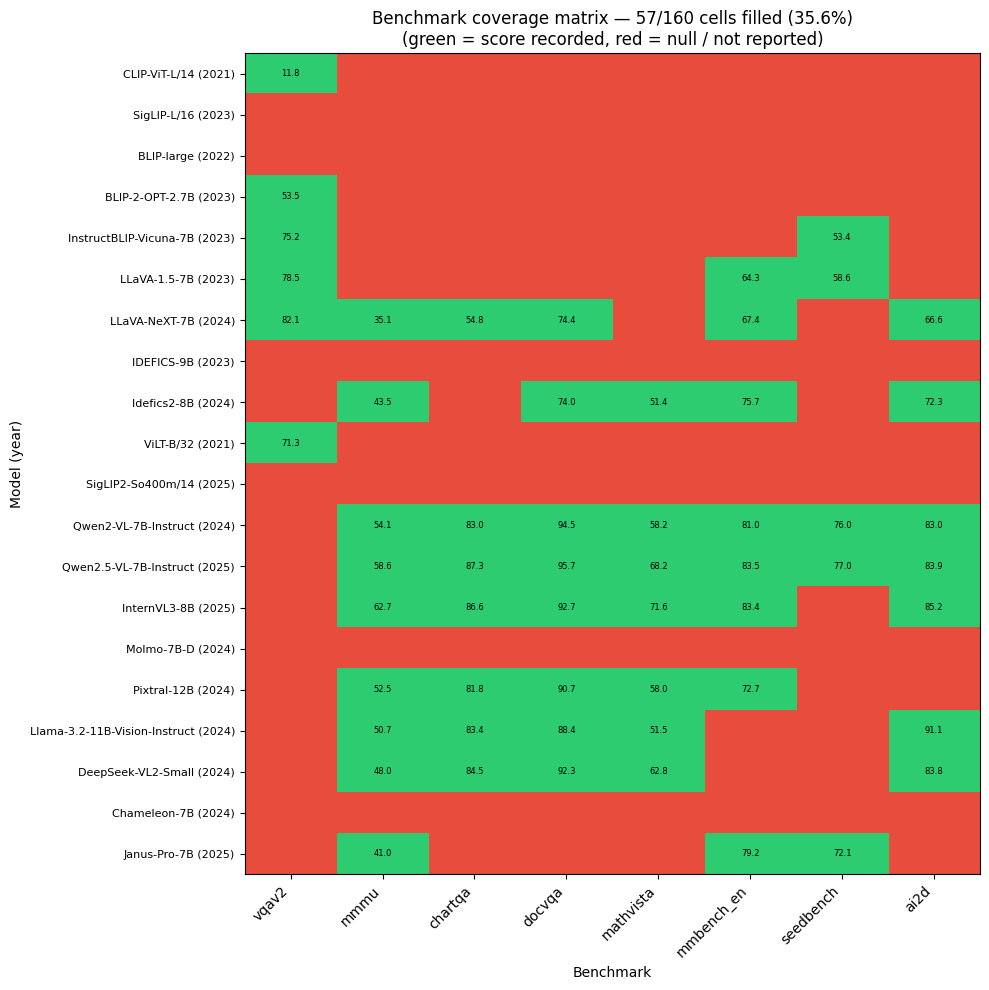

Saved heatmap: /workspace/code_active/outputs/figures/nb12_coverage_heatmap.png


In [28]:
import matplotlib.colors as mcolors

wide = np.zeros((len(bench_data), len(BENCHMARK_SLUGS)), dtype=float)
row_labels = []
for i, block in enumerate(bench_data):
    row_labels.append(f"{block['model_name']} ({block.get('release_year', '?')})")
    for j, slug in enumerate(BENCHMARK_SLUGS):
        score = block['benchmarks'].get(slug, {}).get('score')
        wide[i, j] = 1.0 if score is not None else 0.0

fig, ax = plt.subplots(figsize=(10, 10))
cmap = mcolors.ListedColormap(['#E74C3C', '#2ECC71'])  # red = null, green = filled
im = ax.imshow(wide, aspect='auto', cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(BENCHMARK_SLUGS)))
ax.set_xticklabels(BENCHMARK_SLUGS, rotation=45, ha='right')
ax.set_yticks(range(len(bench_data)))
ax.set_yticklabels(row_labels, fontsize=8)
ax.set_xlabel('Benchmark')
ax.set_ylabel('Model (year)')
ax.set_title(f'Benchmark coverage matrix — {int(wide.sum())}/{wide.size} cells filled ({100*wide.sum()/wide.size:.1f}%)\n(green = score recorded, red = null / not reported)')
# Cell text — show score when filled
for i, block in enumerate(bench_data):
    for j, slug in enumerate(BENCHMARK_SLUGS):
        score = block['benchmarks'].get(slug, {}).get('score')
        if score is not None:
            ax.text(j, i, f'{score:.1f}', ha='center', va='center', fontsize=6, color='black')
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb12_coverage_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved heatmap: {FIG_DIR / "nb12_coverage_heatmap.png"}')

---
## 14. Coverage per benchmark

Inverse view: how many models have data for each benchmark? Useful for deciding which benchmarks have enough coverage to support a correlation analysis in notebook 13.

In [29]:
per_bench_rows = []
for slug, name, desc, metric, url in BENCHMARKS:
    n = sum(1 for block in bench_data if block['benchmarks'].get(slug, {}).get('score') is not None)
    per_bench_rows.append({
        'benchmark':    slug,
        'name':         name,
        'description':  desc,
        'metric':       metric,
        'n_models':     n,
        'pct_models':   round(100 * n / len(bench_data), 1),
        'note':         'sufficient for correlation' if n >= 5 else ('marginal' if n >= 3 else 'INSUFFICIENT — need more entries'),
    })
per_bench_df = pd.DataFrame(per_bench_rows)
per_bench_df

,benchmark,name,description,metric,n_models,pct_models,note
0,vqav2,VQAv2 (test-dev),General VQA,accuracy,6,30.0,sufficient for correlation
1,mmmu,MMMU (val),Multi-discipline knowledge,accuracy,9,45.0,sufficient for correlation
2,chartqa,ChartQA (relaxed),Chart understanding,relaxed_acc,7,35.0,sufficient for correlation
3,docvqa,DocVQA (val ANLS),Document VQA / OCR-heavy,ANLS,8,40.0,sufficient for correlation
4,mathvista,MathVista (test-mini),Math + visual reasoning,accuracy,7,35.0,sufficient for correlation
5,mmbench_en,MMBench-EN (dev),Broad multimodal,accuracy,8,40.0,sufficient for correlation
6,seedbench,SEED-Bench (image),Image perception,accuracy,5,25.0,sufficient for correlation
7,ai2d,AI2D (test),Diagram understanding,accuracy,7,35.0,sufficient for correlation


---
## 15. How to add entries (cheat sheet)

Pattern for each model you transcribe:

1. Open the model's primary paper (URL column in §5).
2. Find the main benchmark table (usually `Table 1` or `Table 4` in §3-§5).
3. Paste a new code cell into this notebook (or add lines to an existing model's cell) like:

```python
MOLMO_URL = 'https://arxiv.org/abs/2409.17146'
set_score('Molmo-7B-D', 'mmmu',       45.3, MOLMO_URL, notes='Table 1 (val)')
set_score('Molmo-7B-D', 'docvqa',     92.2, MOLMO_URL, notes='Table 1 (val ANLS)')
set_score('Molmo-7B-D', 'chartqa',    81.7, MOLMO_URL, notes='Table 1 (relaxed)')
set_score('Molmo-7B-D', 'mathvista',  51.6, MOLMO_URL, notes='Table 1 (test-mini)')
```

4. Re-run §10 (validate), §11 (save), §12-13 (coverage). The YAML + CSV are overwritten on each save.
5. Commit progress in your notes (paper title + table + which benchmarks you transcribed) so you don't double-do the work.

**Rules of thumb:**
* Always cite the paper-section + table number in the `notes` field — makes the correlation analysis auditable.
* If a paper reports two variants of the same benchmark (val vs test-dev), prefer the one the model authors highlight.
* If the paper reports an inflated number that conflicts with the OpenCompass leaderboard, record the leaderboard number with `source_type='leaderboard'` and note the discrepancy.
* When in doubt, leave the cell null — null is information (it tells the reader the paper didn't report it).

---
## Next steps

* When `benchmarks.csv` reaches at least 5 models per benchmark for the benchmarks you care about, open **`13_benchmark_correlations_F11_F14.ipynb`** to compute Spearman/Pearson correlations between structural metrics and benchmark scores.
* The CSV will be re-read fresh each time notebook 13 runs — you can iterate between notebooks 12 and 13 as you add more entries.
* If you want the correlation analysis to support a STRONG claim (e.g. "params correlate with MMMU at ρ > 0.7"), you'll want 10+ models per benchmark. Below 5 the correlation is noisy and should only be reported as a hint, not a finding.
* The provenance MD is your audit trail for the paper's references section — every score has a citable URL.

*End of notebook 12. Pure data-entry; no compute. The next time-cost is the ~3-5 evenings of paper reading that turns this from skeleton into evidence.*